# Tugas Akhir Modul 1 — Text Processing Pipeline

Nama: Annisa Almaghvirah  
NIM: 240306037

Notebook ini menggabungkan materi pertemuan 1–5: eksplorasi corpus, pembersihan teks, tokenisasi, normalisasi, stopword removal, stemming, analisis linguistik, N-Gram, dan Language Model.

Dataset yang digunakan adalah `dataset_preprocessed.csv` dengan kolom teks asli `content` dan kolom hasil preprocessing `processed_text`.


## 1. Dataset Description
Bagian ini memuat informasi dasar dataset. Sumber dataset: [GoPay App Reviews Bahasa Indonesia di Kaggle](https://www.kaggle.com/datasets/pratamas/gopay-app-reviews-bahasa-indonesia).

In [1]:
import os
import re
import math
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams, trigrams
import nltk

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

# Coba beberapa lokasi agar notebook dapat dijalankan dari folder proyek atau folder yang sama.
possible_paths = [
    "review_gopay_newest_sort(1).csv",
    "review_gopay_newest_sort.csv",
    "../dataset/review_gopay_newest_sort.csv",
    "dataset_preprocessed.csv",
    "../pertemuan-03/dataset_preprocessed.csv",
    "D:/NLP/Modul-1/pertemuan-03/dataset_preprocessed.csv",
    "/mnt/data/dataset_preprocessed.csv"
]
csv_path = next((p for p in possible_paths if os.path.exists(p)), None)
if csv_path is None:
    raise FileNotFoundError("Letakkan file review_gopay_newest_sort(1).csv di folder notebook, atau sesuaikan csv_path.")

data = pd.read_csv(csv_path, low_memory=False)
text_column = "content"
if text_column not in data.columns:
    raise KeyError(f"Kolom '{text_column}' tidak ditemukan. Kolom tersedia: {data.columns.tolist()}")

print("File dataset:", csv_path)
print("Ukuran dataset:", data.shape)
print("Nama kolom:", data.columns.tolist())
display(data.head())


File dataset: review_gopay_newest_sort.csv
Ukuran dataset: (123253, 6)
Nama kolom: ['userName', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at']


,userName,content,score,thumbsUpCount,reviewCreatedVersion,at
0,Pengguna Google,Mantap,5,0,1.24.1,2024-07-07 16:58:06
1,Pengguna Google,Bagus dan mudah digunakan,5,0,1.24.1,2024-07-07 16:57:08
2,Pengguna Google,Good,5,0,1.24.1,2024-07-07 16:52:38
3,Pengguna Google,Sangat membantu orang menengah mantap semoga s...,5,0,1.24.1,2024-07-07 16:52:36
4,Pengguna Google,Ga ribet .. Sukaaaa,5,0,1.24.1,2024-07-07 16:52:09


In [ ]:
# Dataset Description
dataset_description = {
    "Nama Dataset": "review_gopay_newest_sort",
    "Sumber": "Kaggle — GoPay App Reviews Bahasa Indonesia (Ardena Afif Pratama)",
    "URL Kaggle": "https://www.kaggle.com/datasets/pratamas/gopay-app-reviews-bahasa-indonesia",
    "Jumlah Data": "123,253",
    "Jumlah Kolom": "6",
    "Kolom Teks": "content",
    "Kolom Label": "Tidak tersedia / tidak terdeteksi",
    "Bahasa": "Bahasa Indonesia (berdasarkan isi komentar)",
    "Jenis Data": "Data teks berbentuk tabel CSV",
}
display(pd.DataFrame(dataset_description.items(), columns=["Aspek", "Keterangan"]))


,Aspek,Keterangan
0,Nama Dataset,review_gopay_newest_sort
1,Sumber,Kaggle — GoPay App Reviews Bahasa Indonesia (A...
2,URL Kaggle,https://www.kaggle.com/datasets/pratamas/gopay...
3,Jumlah Data,"123,253"
4,Jumlah Kolom,6
5,Kolom Teks,content
6,Kolom Label,Tidak tersedia / tidak terdeteksi
7,Bahasa,Bahasa Indonesia (berdasarkan isi komentar)
8,Jenis Data,Data teks berbentuk tabel CSV


## 2. Corpus Exploration

In [ ]:
print("Lima data pertama:")
display(data.head())
print("\nJumlah missing value tiap kolom:")
display(data.isnull().sum().to_frame("Jumlah Missing Value"))

print("\nJumlah baris duplikat seluruh kolom:", data.duplicated().sum())
print("Jumlah teks content duplikat:", data[text_column].dropna().duplicated().sum())

print("\nContoh teks dari kolom content:")
for i, teks in enumerate(data[text_column].dropna().astype(str).head(5), start=1):
    print(f"{i}. {teks}")


Lima data pertama:


,userName,content,score,thumbsUpCount,reviewCreatedVersion,at
0,Pengguna Google,Mantap,5,0,1.24.1,2024-07-07 16:58:06
1,Pengguna Google,Bagus dan mudah digunakan,5,0,1.24.1,2024-07-07 16:57:08
2,Pengguna Google,Good,5,0,1.24.1,2024-07-07 16:52:38
3,Pengguna Google,Sangat membantu orang menengah mantap semoga s...,5,0,1.24.1,2024-07-07 16:52:36
4,Pengguna Google,Ga ribet .. Sukaaaa,5,0,1.24.1,2024-07-07 16:52:09



Jumlah missing value tiap kolom:


,Jumlah Missing Value
userName,0
content,0
score,0
thumbsUpCount,0
reviewCreatedVersion,15928
at,0



Jumlah baris duplikat seluruh kolom: 2
Jumlah teks content duplikat: 44822

Contoh teks dari kolom content:
1. Mantap
2. Bagus dan mudah digunakan
3. Good
4. Sangat membantu orang menengah mantap semoga sukses terus gopay
5. Ga ribet .. Sukaaaa


## 3. Data Cleaning
Teks kosong dibuang dan teks duplikat pada kolom `content` dihilangkan untuk analisis corpus. Data asli tetap tersedia pada variabel `data`.

In [4]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[\r\n\t]+", " ", text)
    text = re.sub(r"[^\w\s.,!?'-]", " ", text, flags=re.UNICODE)
    text = re.sub(r"\s+", " ", text).strip()
    return text

corpus = data.copy()
TEXT_COLUMN = "content"

corpus["clean_text"] = corpus[TEXT_COLUMN].fillna("").apply(clean_text)

display(corpus[[TEXT_COLUMN, "clean_text"]].head(10))

,content,clean_text
0,Mantap,mantap
1,Bagus dan mudah digunakan,bagus dan mudah digunakan
2,Good,good
3,Sangat membantu orang menengah mantap semoga s...,sangat membantu orang menengah mantap semoga s...
4,Ga ribet .. Sukaaaa,ga ribet .. sukaaaa
5,Sangat membantu,sangat membantu
6,Mantap pakay gopay,mantap pakay gopay
7,mantap mantap mantap,mantap mantap mantap
8,Layanan sang Mudah Dan Sangat Memuaskan,layanan sang mudah dan sangat memuaskan
9,Berbisnis,berbisnis


## 4. Sentence Segmentation

In [5]:
import re
import pandas as pd

def safe_sent_tokenize(text):
    if pd.isna(text):
        return []

    text = str(text).strip()
    if not text:
        return []

    # Pisahkan kalimat setelah tanda titik, tanya, atau seru
    return [
        sentence.strip()
        for sentence in re.split(r"(?<=[.!?])\s+", text)
        if sentence.strip()
    ]

corpus["sentences"] = corpus[TEXT_COLUMN].apply(safe_sent_tokenize)

display(corpus[[TEXT_COLUMN, "sentences"]].head(10))
print("Total kalimat tersegmentasi:", int(corpus["sentences"].apply(len).sum()))


,content,sentences
0,Mantap,[Mantap]
1,Bagus dan mudah digunakan,[Bagus dan mudah digunakan]
2,Good,[Good]
3,Sangat membantu orang menengah mantap semoga s...,[Sangat membantu orang menengah mantap semoga ...
4,Ga ribet .. Sukaaaa,"[Ga ribet .., Sukaaaa]"
5,Sangat membantu,[Sangat membantu]
6,Mantap pakay gopay,[Mantap pakay gopay]
7,mantap mantap mantap,[mantap mantap mantap]
8,Layanan sang Mudah Dan Sangat Memuaskan,[Layanan sang Mudah Dan Sangat Memuaskan]
9,Berbisnis,[Berbisnis]


Total kalimat tersegmentasi: 141621


## 5. Tokenization

In [7]:
from nltk.tokenize import word_tokenize

def tokenize_text(text):
    return word_tokenize(str(text))

corpus["tokens_raw"] = corpus[text_column].apply(tokenize_text)
corpus["jumlah_token_raw"] = corpus["tokens_raw"].apply(len)
display(corpus[[text_column, "tokens_raw", "jumlah_token_raw"]].head())

,content,tokens_raw,jumlah_token_raw
0,Mantap,[Mantap],1
1,Bagus dan mudah digunakan,"[Bagus, dan, mudah, digunakan]",4
2,Good,[Good],1
3,Sangat membantu orang menengah mantap semoga s...,"[Sangat, membantu, orang, menengah, mantap, se...",9
4,Ga ribet .. Sukaaaa,"[Ga, ribet, .., Sukaaaa]",4


### Character Tokenization
Selain memecah teks menjadi kata, bagian ini juga memecah teks menjadi karakter agar jumlah karakter dan contoh hasilnya dapat diperiksa.

In [8]:
def character_tokenize(text):
    return list(str(text))

corpus["characters"] = corpus[text_column].apply(character_tokenize)
corpus["jumlah_karakter_per_dokumen"] = corpus["characters"].apply(len)
display(corpus[[text_column, "characters", "jumlah_karakter_per_dokumen"]].head())
print("Contoh jumlah karakter dokumen pertama:", corpus["jumlah_karakter_per_dokumen"].iloc[0] if len(corpus) else 0)

,content,characters,jumlah_karakter_per_dokumen
0,Mantap,"[M, a, n, t, a, p]",6
1,Bagus dan mudah digunakan,"[B, a, g, u, s, , d, a, n, , m, u, d, a, h, ...",25
2,Good,"[G, o, o, d]",4
3,Sangat membantu orang menengah mantap semoga s...,"[S, a, n, g, a, t, , m, e, m, b, a, n, t, u, ...",63
4,Ga ribet .. Sukaaaa,"[G, a, , r, i, b, e, t, , ., ., , S, u, k, ...",19


Contoh jumlah karakter dokumen pertama: 6


## 6. Normalization
Normalisasi pada notebook ini mencakup lowercase, penghapusan URL, mention, hashtag, angka, tanda baca, dan perapian spasi. Penyesuaian dapat dilakukan sesuai tujuan analisis.

In [9]:
def case_folding(text):
    return str(text).lower()

def clean_text(text):
    text = case_folding(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"\d+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

corpus["normalized_text"] = corpus[text_column].apply(clean_text)
corpus["tokens"] = corpus["normalized_text"].apply(tokenize_text)
display(corpus[[text_column, "normalized_text", "tokens"]].head())


,content,normalized_text,tokens
0,Mantap,mantap,[mantap]
1,Bagus dan mudah digunakan,bagus dan mudah digunakan,"[bagus, dan, mudah, digunakan]"
2,Good,good,[good]
3,Sangat membantu orang menengah mantap semoga s...,sangat membantu orang menengah mantap semoga s...,"[sangat, membantu, orang, menengah, mantap, se..."
4,Ga ribet .. Sukaaaa,ga ribet sukaaaa,"[ga, ribet, sukaaaa]"


## 7. Stopword Removal

In [10]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("indonesian"))
# Tambahkan kata hanya jika memang diperlukan untuk konteks dataset.
def remove_stopwords(tokens):
    return [token for token in tokens if token.lower() not in stop_words]

corpus["tokens_no_stopword"] = corpus["tokens"].apply(remove_stopwords)
display(corpus[[text_column, "tokens", "tokens_no_stopword"]].head())


,content,tokens,tokens_no_stopword
0,Mantap,[mantap],[mantap]
1,Bagus dan mudah digunakan,"[bagus, dan, mudah, digunakan]","[bagus, mudah]"
2,Good,[good],[good]
3,Sangat membantu orang menengah mantap semoga s...,"[sangat, membantu, orang, menengah, mantap, se...","[membantu, orang, menengah, mantap, semoga, su..."
4,Ga ribet .. Sukaaaa,"[ga, ribet, sukaaaa]","[ga, ribet, sukaaaa]"


### Analisis Stopword
Bagian ini membandingkan jumlah token sebelum dan sesudah stopword removal. Kata stopword tidak selalu harus dihapus; hasilnya perlu dilihat sesuai tujuan analisis.

In [11]:
corpus["jumlah_token_sebelum_stopword"] = corpus["tokens"].apply(len)
corpus["jumlah_token_sesudah_stopword"] = corpus["tokens_no_stopword"].apply(len)
print("Total token sebelum stopword removal:", int(corpus["jumlah_token_sebelum_stopword"].sum()))
print("Total token sesudah stopword removal:", int(corpus["jumlah_token_sesudah_stopword"].sum()))
print("Contoh stopword yang digunakan:", sorted(list(stop_words))[:20])
display(corpus[[text_column, "tokens", "tokens_no_stopword"]].head())

Total token sebelum stopword removal: 797558
Total token sesudah stopword removal: 538224
Contoh stopword yang digunakan: ['ada', 'adalah', 'adanya', 'adapun', 'agak', 'agaknya', 'agar', 'akan', 'akankah', 'akhir', 'akhiri', 'akhirnya', 'aku', 'akulah', 'amat', 'amatlah', 'anda', 'andalah', 'antar', 'antara']


,content,tokens,tokens_no_stopword
0,Mantap,[mantap],[mantap]
1,Bagus dan mudah digunakan,"[bagus, dan, mudah, digunakan]","[bagus, mudah]"
2,Good,[good],[good]
3,Sangat membantu orang menengah mantap semoga s...,"[sangat, membantu, orang, menengah, mantap, se...","[membantu, orang, menengah, mantap, semoga, su..."
4,Ga ribet .. Sukaaaa,"[ga, ribet, sukaaaa]","[ga, ribet, sukaaaa]"


## 8. Stemming

In [12]:
import pandas as pd
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

try:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    stemmer = StemmerFactory().create_stemmer()
    STEMMING_AVAILABLE = True
except Exception as exc:
    stemmer = None
    STEMMING_AVAILABLE = False
    print("Sastrawi belum tersedia; fallback tanpa stemming.", exc)

stop_words = set(stopwords.words("indonesian"))

def stem_tokens(tokens):
    if not STEMMING_AVAILABLE:
        return list(tokens)
    return [stemmer.stem(str(token)) for token in tokens]

def tokenize_and_clean(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words and t.strip()]
    return tokens

# Kalau mau hanya dari kolom content
corpus["tokens_no_stopword"] = corpus["content"].fillna("").apply(tokenize_and_clean)
corpus["stemmed_tokens"] = corpus["tokens_no_stopword"].apply(stem_tokens)
corpus["processed_text"] = corpus["stemmed_tokens"].apply(lambda x: " ".join(x))

display(corpus[["content", "tokens_no_stopword", "stemmed_tokens", "processed_text"]].head(10))
print("Stemming Sastrawi aktif:", STEMMING_AVAILABLE)

,content,tokens_no_stopword,stemmed_tokens,processed_text
0,Mantap,[mantap],[mantap],mantap
1,Bagus dan mudah digunakan,"[bagus, mudah]","[bagus, mudah]",bagus mudah
2,Good,[good],[good],good
3,Sangat membantu orang menengah mantap semoga s...,"[membantu, orang, menengah, mantap, semoga, su...","[bantu, orang, tengah, mantap, moga, sukses, g...",bantu orang tengah mantap moga sukses gopay
4,Ga ribet .. Sukaaaa,"[ga, ribet, sukaaaa]","[ga, ribet, sukaaaa]",ga ribet sukaaaa
5,Sangat membantu,[membantu],[bantu],bantu
6,Mantap pakay gopay,"[mantap, pakay, gopay]","[mantap, pakay, gopay]",mantap pakay gopay
7,mantap mantap mantap,"[mantap, mantap, mantap]","[mantap, mantap, mantap]",mantap mantap mantap
8,Layanan sang Mudah Dan Sangat Memuaskan,"[layanan, sang, mudah, memuaskan]","[layan, sang, mudah, muas]",layan sang mudah muas
9,Berbisnis,[berbisnis],[bisnis],bisnis


Stemming Sastrawi aktif: True


In [ ]:
# Hindari menyimpan list Python sebagai struktur yang sulit dibaca CSV
from pathlib import Path

OUTPUT_DIR = Path("../output")  # dari folder pertemuan-03 menuju Modul-1/output
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_df = corpus.copy()
for col in ["kalimat_list", "tokens_raw", "characters", "sentences", "tokens", "normalized_tokens", "tokens_no_stopword", "stemmed_tokens"]:
    if col in output_df.columns:
        output_df[col] = output_df[col].apply(lambda x: " || ".join(map(str, x)) if isinstance(x, list) else x)
output_file = OUTPUT_DIR / "dataset_preprocessed.csv"
output_df.to_csv(output_file, index=False, encoding="utf-8-sig")
print("Tersimpan:", output_file.resolve())
print("Jumlah baris:", len(output_df))

Tersimpan: D:\NLP\output\dataset_preprocessed.csv
Jumlah baris: 123253


## 9. POS Tagging
Bagian ini menggunakan model Stanza bahasa Indonesia melalui spaCy-Stanza, mengikuti pendekatan pada notebook pertemuan linguistik. Jalankan instalasi dan unduh model jika belum tersedia.

In [ ]:
import pandas as pd
import stanza
from IPython.display import display

# Muat model POS dan dependency Bahasa Indonesia
nlp = stanza.Pipeline(
    lang="id",
    processors="tokenize,mwt,pos,lemma,depparse",
    use_gpu=False,
)

print("Model Stanza Bahasa Indonesia berhasil dimuat.")

# POS tagging untuk 10 review pertama di kolom content
pos_rows = []

for index, kalimat in corpus["content"].dropna().head(10).astype(str).items():
    doc = nlp(kalimat)

    for sentence in doc.sentences:
        words_by_id = {word.id: word for word in sentence.words}

        for word in sentence.words:
            head_word = (
                words_by_id[word.head].text
                if word.head in words_by_id
                else word.text
            )

            pos_rows.append({
                "Kalimat": kalimat,
                "POS": word.upos,
                "POS Tag": word.xpos or "",
                "Lemma": word.lemma or "",
                "Dependency": word.deprel or "",
                "Head": head_word,
            })

pos_table = pd.DataFrame(pos_rows)
display(pos_table)

2026-10-25 22:06:06 INFO: Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


2026-10-25 22:06:08 INFO: Downloaded file to C:\Users\ASUS\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\resources.json
2026-10-25 22:06:11 INFO: Loading these models for language: id (Indonesian):
| Processor | Package      |
----------------------------
| tokenize  | gsd_nocharlm |
| mwt       | gsd          |
| pos       | gsd_charlm   |
| lemma     | gsd_nocharlm |
| depparse  | gsd_charlm   |

2026-10-25 22:06:11 INFO: Using device: cpu
2026-10-25 22:06:11 INFO: Loading: tokenize
2026-10-25 22:06:17 INFO: Loading: mwt
2026-10-25 22:06:18 INFO: Loading: pos
2026-10-25 22:06:23 INFO: Loading: lemma
2026-10-25 22:06:24 INFO: Loading: depparse
2026-10-25 22:06:25 INFO: Done loading processors!


Model Stanza Bahasa Indonesia berhasil dimuat.


,Kalimat,POS,POS Tag,Lemma,Dependency,Head
0,Mantap,PROPN,ASP,mantap,root,Mantap
1,Bagus dan mudah digunakan,ADJ,ASP,bagus,root,Bagus
2,Bagus dan mudah digunakan,CCONJ,H--,dan,cc,digunakan
3,Bagus dan mudah digunakan,ADJ,ASP,mudah,amod,digunakan
4,Bagus dan mudah digunakan,VERB,VSP,guna,conj,Bagus
5,Good,PROPN,F--,good,root,Good
6,Sangat membantu orang menengah mantap semoga s...,ADV,D--,sangat,advmod,membantu
7,Sangat membantu orang menengah mantap semoga s...,VERB,VSA,bantu,root,membantu
8,Sangat membantu orang menengah mantap semoga s...,NOUN,NSD,orang,obj,membantu
9,Sangat membantu orang menengah mantap semoga s...,ADJ,ASP,menengah,amod,orang


## 10. Dependency Parsing

In [ ]:
import pandas as pd
from IPython.display import display

# Ambil 10 review pertama dari kolom content
linguistic_samples = (
    corpus["content"]
    .dropna()
    .head(10)
    .astype(str)
    .tolist()
)

dependency_results = []

if nlp is not None:
    for idx, text in enumerate(linguistic_samples, start=1):
        doc = nlp(text)

        for sentence in doc.sentences:
            words_by_id = {word.id: word for word in sentence.words}

            for word in sentence.words:
                if word.head == 0:
                    head_text = word.text
                else:
                    head_text = words_by_id[word.head].text

                dependency_results.append({
                    "Sampel": idx,
                    "Teks": text,
                    "Token": word.text,
                    "POS": word.upos,
                    "POS Tag": word.xpos or "",
                    "Dependency": word.deprel or "",
                    "Head": head_text,
                    "Lemma": word.lemma or "",
                })

    dependency_df = pd.DataFrame(dependency_results)
    display(dependency_df.head(100))
else:
    print("Model belum dimuat. Jalankan sel yang membuat nlp terlebih dahulu.")

,Sampel,Teks,Token,POS,POS Tag,Dependency,Head,Lemma
0,1,Mantap,Mantap,PROPN,ASP,root,Mantap,mantap
1,2,Bagus dan mudah digunakan,Bagus,ADJ,ASP,root,Bagus,bagus
2,2,Bagus dan mudah digunakan,dan,CCONJ,H--,cc,digunakan,dan
3,2,Bagus dan mudah digunakan,mudah,ADJ,ASP,amod,digunakan,mudah
4,2,Bagus dan mudah digunakan,digunakan,VERB,VSP,conj,Bagus,guna
5,3,Good,Good,PROPN,F--,root,Good,good
6,4,Sangat membantu orang menengah mantap semoga s...,Sangat,ADV,D--,advmod,membantu,sangat
7,4,Sangat membantu orang menengah mantap semoga s...,membantu,VERB,VSA,root,membantu,bantu
8,4,Sangat membantu orang menengah mantap semoga s...,orang,NOUN,NSD,obj,membantu,orang
9,4,Sangat membantu orang menengah mantap semoga s...,menengah,ADJ,ASP,amod,orang,menengah


In [ ]:
# Visualisasi dependency tree untuk sampel pertama yang terdiri dari beberapa kata
from spacy import displacy
from IPython.display import HTML, display

if nlp is None:
    print("Model belum dimuat. Jalankan sel yang membuat nlp terlebih dahulu.")
else:
    samples = corpus["content"].dropna().astype(str).tolist()
    kalimat = next(
        (text for text in samples if len(text.split()) >= 3),
        None,
    )

    if kalimat is None:
        print("Tidak ada review dengan minimal 3 kata di kolom content.")
    else:
        doc = nlp(kalimat)

        if not doc.sentences:
            print("Sampel tidak menghasilkan kalimat.")
        else:
            words = doc.sentences[0].words
            word_index = {word.id: i for i, word in enumerate(words)}

            parsed = {
                "words": [
                    {"text": word.text, "tag": word.upos}
                    for word in words
                ],
                "arcs": [],
            }

            for i, word in enumerate(words):
                if word.head == 0 or word.head not in word_index:
                    continue

                head_index = word_index[word.head]
                parsed["arcs"].append({
                    "start": min(i, head_index),
                    "end": max(i, head_index),
                    "label": "",
                    "dir": "left" if i < head_index else "right",
                })

            print("Sampel:", kalimat)
            html = displacy.render(
                [parsed],
                style="dep",
                manual=True,
                options={"compact": True},
            )
            display(HTML(html))

Sampel: Bagus dan mudah digunakan


<IPython.core.display.HTML object>

## 11. N-Gram
N-gram dibuat per dokumen agar pasangan kata tidak terbentuk dari gabungan akhir dokumen satu dengan awal dokumen lain.

In [ ]:
import pandas as pd
from collections import Counter
from nltk.util import bigrams, trigrams
from IPython.display import display

# Muat ulang dataset Modul 2
df = pd.read_csv("D:/NLP/Modul-2/dataset_preprocessed.csv")
text_column = "processed_text"

documents_tokens = (
    df[text_column]
    .fillna("")
    .astype(str)
    .apply(str.split)
)

unigram_frequency = Counter()
bigram_frequency = Counter()
trigram_frequency = Counter()

for tokens in documents_tokens:
    unigram_frequency.update(tokens)
    bigram_frequency.update(bigrams(tokens))
    trigram_frequency.update(trigrams(tokens))

top_unigram = pd.DataFrame(
    unigram_frequency.most_common(20),
    columns=["Unigram", "Frekuensi"],
)

top_bigram = pd.DataFrame(
    [(" ".join(gram), count) for gram, count in bigram_frequency.most_common(20)],
    columns=["Bigram", "Frekuensi"],
)

top_trigram = pd.DataFrame(
    [(" ".join(gram), count) for gram, count in trigram_frequency.most_common(20)],
    columns=["Trigram", "Frekuensi"],
)

print("Top 20 Unigram")
display(top_unigram)

print("Top 20 Bigram")
display(top_bigram)

print("Top 20 Trigram")
display(top_trigram)

Top 20 Unigram


,Unigram,Frekuensi
0,gopay,20327
1,aplikasi,15681
2,bagus,14955
3,mantap,13770
4,mudah,13351
5,bantu,11089
6,nya,8868
7,transaksi,7587
8,ok,6879
9,transfer,6219


Top 20 Bigram


,Bigram,Frekuensi
0,mudah transaksi,1701
1,top up,1613
2,aplikasi gopay,1598
3,aplikasi bagus,1423
4,aplikasi nya,1180
5,terima kasih,1055
6,pakai gopay,993
7,gopay pinjam,991
8,pake gopay,963
9,transfer bank,958


Top 20 Trigram


,Trigram,Frekuensi
0,terima kasih gopay,283
1,aplikasi nya bagus,276
2,upgrade gopay plus,250
3,is the best,211
4,top up saldo,185
5,aplikasi yg bagus,166
6,gratis biaya admin,164
7,aplikasi bagus mudah,159
8,gopay mudah transaksi,136
9,apk nya bagus,132


## 12. Language Model
Model bigram sederhana memperkirakan kata berikutnya berdasarkan kata sebelumnya. Laplace smoothing membantu memberi probabilitas bukan nol untuk bigram yang belum pernah ditemukan.

In [ ]:
vocab = set(unigram_frequency)
vocab_size = max(len(vocab), 1)
total_tokens = sum(unigram_frequency.values())

unigram_probability = {
    word: count / total_tokens
    for word, count in unigram_frequency.items()
} if total_tokens else {}

def bigram_probability(word1, word2):
    denominator = unigram_frequency[word1]
    if denominator == 0:
        return 0.0
    return bigram_frequency[(word1, word2)] / denominator

def smoothed_bigram_probability(word1, word2):
    return (bigram_frequency[(word1, word2)] + 1) / (unigram_frequency[word1] + vocab_size)

def predict_next_word(context_word, top_n=5):
    candidates = [
        (word2, smoothed_bigram_probability(context_word, word2))
        for word1, word2 in bigram_frequency if word1 == context_word
    ]
    candidates.sort(key=lambda item: item[1], reverse=True)
    return candidates[:top_n]

print("Ukuran vocabulary:", vocab_size)
print("Jumlah token:", total_tokens)
if unigram_frequency:
    word_example = unigram_frequency.most_common(1)[0][0]
    print("Contoh kata:", word_example)
    print("Probabilitas unigram:", round(unigram_probability[word_example], 6))
    print("Prediksi kata setelahnya:", predict_next_word(word_example))


Ukuran vocabulary: 32680
Jumlah token: 537966
Contoh kata: gopay
Probabilitas unigram: 0.037785
Prediksi kata setelahnya: [('pinjam', 0.018714509404418284), ('plus', 0.010545776972852642), ('mudah', 0.010451449808515857), ('later', 0.009225196672137642), ('bantu', 0.009074273209198786)]


In [ ]:
def sentence_perplexity(sentence):
    words = str(sentence).lower().split()
    if len(words) < 2:
        return float("nan")
    log_probability = 0.0
    for w1, w2 in zip(words[:-1], words[1:]):
        p = smoothed_bigram_probability(w1, w2)
        log_probability += math.log(p)
    return math.exp(-log_probability / (len(words) - 1))

contoh_tokens = documents_tokens.iloc[0] if not documents_tokens.empty else []
contoh_kalimat = " ".join(contoh_tokens[:12])
print("Contoh kalimat/token:", contoh_kalimat)
print("Perplexity bigram dengan Laplace smoothing:", sentence_perplexity(contoh_kalimat) if contoh_kalimat else "Tidak ada token")


Contoh kalimat/token: mantap
Perplexity bigram dengan Laplace smoothing: nan


### Pengujian Language Model dan Error Analysis
Pengujian berikut mencakup probabilitas beberapa kata, lima kalimat uji, lima konteks prediksi, zero probability, smoothing, dan perplexity. Kalimat uji diambil dari dokumen hasil preprocessing agar kosakatanya relevan dengan corpus.

In [ ]:
# Probabilitas unigram untuk minimal 5 kata yang paling sering muncul
print("Probabilitas unigram untuk 5 kata:")
prob_rows = []
for word, count in unigram_frequency.most_common(5):
    prob_rows.append({"Kata": word, "Frekuensi": count,
                      "Probabilitas Unigram": unigram_probability.get(word, 0.0)})
display(pd.DataFrame(prob_rows))

# Contoh zero probability dan perbandingan setelah Laplace smoothing
if vocab:
    context_example = unigram_frequency.most_common(1)[0][0]
    unseen_candidate = "__kata_tidak_ditemukan__"
    print("Contoh konteks:", context_example)
    print("Bigram tanpa smoothing untuk pasangan yang tidak ditemukan:", bigram_probability(context_example, unseen_candidate))
    print("Bigram dengan Laplace smoothing:", smoothed_bigram_probability(context_example, unseen_candidate))

# Lima kalimat uji dari hasil tokenisasi/stemming; hitung perplexity masing-masing
sentences_test = [" ".join(tokens[:12]) for tokens in documents_tokens if len(tokens) >= 2][:5]
perplexity_rows = []
for i, sentence in enumerate(sentences_test, start=1):
    perplexity_rows.append({"No": i, "Kalimat Uji": sentence,
                            "Perplexity Bigram (Laplace)": sentence_perplexity(sentence)})
print("Perplexity untuk setiap kalimat uji:")
display(pd.DataFrame(perplexity_rows))

# Prediksi kata berikutnya untuk minimal 5 kata konteks yang punya kelanjutan bigram
contexts = list(dict.fromkeys([w1 for w1, _ in bigram_frequency]))[:5]
prediction_rows = []
for context in contexts:
    prediction_rows.append({"Konteks": context,
                            "Prediksi Kata Berikutnya": predict_next_word(context, top_n=5)})
print("Prediksi untuk maksimal 5 konteks:")
display(pd.DataFrame(prediction_rows))

# Perbandingan sederhana unigram, bigram, dan trigram
comparison = pd.DataFrame([
    {"Model": "Unigram", "Jumlah N-gram Unik": len(unigram_frequency), "Panjang konteks": 0},
    {"Model": "Bigram", "Jumlah N-gram Unik": len(bigram_frequency), "Panjang konteks": 1},
    {"Model": "Trigram", "Jumlah N-gram Unik": len(trigram_frequency), "Panjang konteks": 2},
])
display(comparison)

Probabilitas unigram untuk 5 kata:


,Kata,Frekuensi,Probabilitas Unigram
0,gopay,20036,0.040404
1,aplikasi,14830,0.029906
2,mudah,12536,0.025280
3,nya,9068,0.018286
4,bagus,8388,0.016915


Contoh konteks: gopay
Bigram tanpa smoothing untuk pasangan yang tidak ditemukan: 0.0
Bigram dengan Laplace smoothing: 2.332089552238806e-05
Perplexity untuk setiap kalimat uji:


,No,Kalimat Uji,Perplexity Bigram (Laplace)
0,1,bagus mudah,53.571184
1,2,bantu orang tengah mantap moga sukses gopay,1072.328335
2,3,ga ribet sukaaaa,935.992421
3,4,mantap pakay gopay,3829.797691
4,5,mantap mantap mantap,780.378378


Prediksi untuk maksimal 5 konteks:


,Konteks,Prediksi Kata Berikutnya
0,bagus,"[(mudah, 0.018666752049180328), (banget, 0.018..."
1,bantu,"[(transaksi, 0.01897767523478374), (mudah, 0.0..."
2,orang,"[(yg, 0.001954452753229096), (orang, 0.0007647..."
3,tengah,"[(mantap, 8.750054687841798e-05), (duit, 8.750..."
4,mantap,"[(mudah, 0.009766572002493593), (gopay, 0.0082..."


,Model,Jumlah N-gram Unik,Panjang konteks
0,Unigram,22844,0
1,Bigram,169437,1
2,Trigram,283246,2


## 13. Visualization

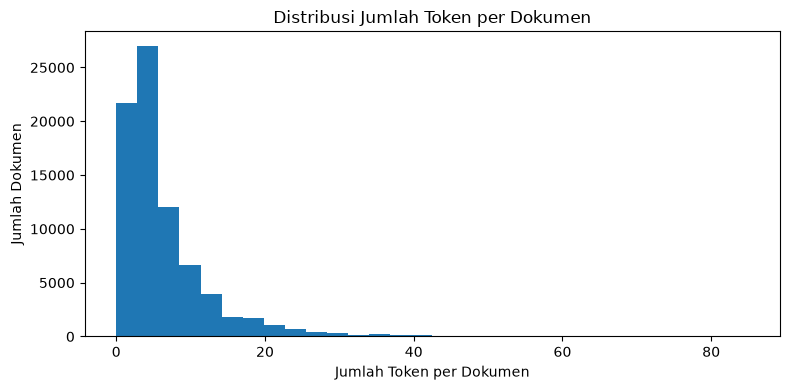

Kolom score/rating tidak tersedia; visualisasi rating dilewati.


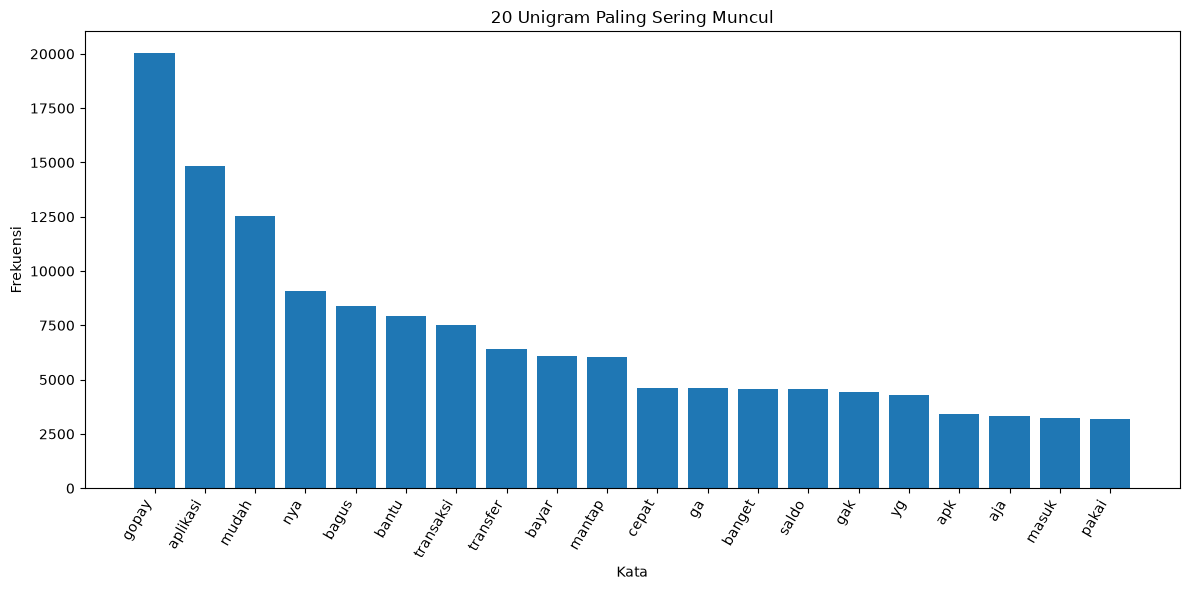

In [ ]:
# Panjang dokumen berdasarkan jumlah token setelah preprocessing
import matplotlib.pyplot as plt

token_lengths = corpus["stemmed_tokens"].apply(
    lambda tokens: len(tokens) if isinstance(tokens, list) else len(str(tokens).split())
)

plt.figure(figsize=(8, 4))
plt.hist(token_lengths, bins=30)
plt.title("Distribusi Jumlah Token per Dokumen")
plt.xlabel("Jumlah Token per Dokumen")
plt.ylabel("Jumlah Dokumen")
plt.tight_layout()
plt.show()

# Dataset tidak memiliki label sentimen. Kolom score (jika ada) hanya rating, bukan label.
if "score" in data.columns:
    data["score"].value_counts(dropna=False).sort_index().plot(kind="bar", figsize=(8, 4))
    plt.title("Distribusi Rating GoPay (score), bukan Label Sentimen")
    plt.xlabel("Rating (bintang)")
    plt.ylabel("Jumlah Ulasan")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom score/rating tidak tersedia; visualisasi rating dilewati.")

top_words = unigram_frequency.most_common(20)
if top_words:
    labels, values = zip(*top_words)
    plt.figure(figsize=(12, 6))
    plt.bar(labels, values)
    plt.title("20 Unigram Paling Sering Muncul")
    plt.xlabel("Kata")
    plt.ylabel("Frekuensi")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Belum ada unigram untuk divisualisasikan.")


## 14. Analysis
Jalankan sel berikut untuk menghasilkan ringkasan angka yang bisa digunakan dalam pembahasan.

In [ ]:
TEXT_COLUMN = "content"

requested_columns = [
    TEXT_COLUMN,
    "clean_text",
    "normalized_text",
    "text_no_stopword",
    "processed_text",
]

analysis_columns = [
    col for col in requested_columns
    if col in corpus.columns
]

missing_columns = [
    col for col in requested_columns
    if col not in corpus.columns
]

print("Kolom yang tersedia:", analysis_columns)
if missing_columns:
    print("Kolom yang belum ada:", missing_columns)

display(corpus[analysis_columns].head(10))

Kolom yang tersedia: ['content', 'normalized_text', 'processed_text']
Kolom yang belum ada: ['clean_text', 'text_no_stopword']


,content,normalized_text,processed_text
0,Mantap,mantap,mantap
1,Bagus dan mudah digunakan,bagus dan mudah digunakan,bagus mudah
2,Good,good,good
3,Sangat membantu orang menengah mantap semoga s...,sangat membantu orang menengah mantap semoga s...,bantu orang tengah mantap moga sukses gopay
4,Ga ribet .. Sukaaaa,ga ribet sukaaaa,ga ribet sukaaaa
5,Sangat membantu,sangat membantu,bantu
6,Mantap pakay gopay,mantap pakay gopay,mantap pakay gopay
7,mantap mantap mantap,mantap mantap mantap,mantap mantap mantap
8,Layanan sang Mudah Dan Sangat Memuaskan,layanan sang mudah dan sangat memuaskan,layan sang mudah muas
9,Berbisnis,berbisnis,bisnis


### Error Analysis
Periksa beberapa hasil preprocessing untuk menemukan kemungkinan kesalahan, misalnya kata informal yang berubah kurang tepat, singkatan, kata negasi yang terhapus, atau kalimat yang tidak tersegmentasi dengan baik.

In [ ]:
text_column = "content"

requested_columns = [
    text_column,
    "normalized_text",
    "tokens_no_stopword",
    "stemmed_tokens",
]

available_columns = [
    col for col in requested_columns
    if col in corpus.columns
]

missing_columns = [
    col for col in requested_columns
    if col not in corpus.columns
]

print("Kolom yang ditampilkan:", available_columns)
if missing_columns:
    print("Kolom yang belum tersedia:", missing_columns)

error_check = corpus[available_columns].head(10).copy()
display(error_check)

Kolom yang ditampilkan: ['content', 'normalized_text', 'tokens_no_stopword', 'stemmed_tokens']


,content,normalized_text,tokens_no_stopword,stemmed_tokens
0,Mantap,mantap,[mantap],[mantap]
1,Bagus dan mudah digunakan,bagus dan mudah digunakan,"[bagus, mudah]","[bagus, mudah]"
2,Good,good,[good],[good]
3,Sangat membantu orang menengah mantap semoga s...,sangat membantu orang menengah mantap semoga s...,"[membantu, orang, menengah, mantap, semoga, su...","[bantu, orang, tengah, mantap, moga, sukses, g..."
4,Ga ribet .. Sukaaaa,ga ribet sukaaaa,"[ga, ribet, sukaaaa]","[ga, ribet, sukaaaa]"
5,Sangat membantu,sangat membantu,[membantu],[bantu]
6,Mantap pakay gopay,mantap pakay gopay,"[mantap, pakay, gopay]","[mantap, pakay, gopay]"
7,mantap mantap mantap,mantap mantap mantap,"[mantap, mantap, mantap]","[mantap, mantap, mantap]"
8,Layanan sang Mudah Dan Sangat Memuaskan,layanan sang mudah dan sangat memuaskan,"[layanan, sang, mudah, memuaskan]","[layan, sang, mudah, muas]"
9,Berbisnis,berbisnis,[berbisnis],[bisnis]


## Contoh Tabel Preprocessing 20 Data Pertama

Bagian ini menampilkan 20 ulasan dari kolom `content` secara berurutan, sesuai dataset GoPay yang digunakan dalam laporan. Setiap tahap memakai hasil tahap sebelumnya: teks asli → case folding → cleaning → tokenisasi → stopword removal → stemming. Tabel ini hanya contoh proses pada 20 data pertama, bukan seluruh corpus.


In [ ]:
# Membuat tabel contoh dari 20 ulasan pertama yang tidak kosong
contoh = data.dropna(subset=[text_column]).copy()
contoh[text_column] = contoh[text_column].astype(str).str.strip()
contoh = contoh[contoh[text_column] != ""].head(20).copy()

contoh_preprocessing = pd.DataFrame()
contoh_preprocessing["Teks Asli"] = contoh[text_column]
contoh_preprocessing["Case Folding"] = contoh[text_column].apply(case_folding)
contoh_preprocessing["Cleaning"] = contoh_preprocessing["Case Folding"].apply(clean_text)
contoh_preprocessing["Tokenisasi"] = contoh_preprocessing["Cleaning"].apply(tokenize_text).apply(lambda x: " ".join(x))
contoh_preprocessing["Stopword Removal"] = contoh_preprocessing["Cleaning"].apply(tokenize_text).apply(remove_stopwords).apply(lambda x: " ".join(x))
contoh_preprocessing["Stemming"] = contoh_preprocessing["Cleaning"].apply(tokenize_text).apply(remove_stopwords).apply(stem_tokens).apply(lambda x: " ".join(x))

pd.set_option("display.max_colwidth", 120)
display(contoh_preprocessing.reset_index(drop=True))
print("Jumlah contoh yang ditampilkan:", len(contoh_preprocessing))


,Teks Asli,Case Folding,Cleaning,Tokenisasi,Stopword Removal,Stemming
0,Mantap,mantap,mantap,mantap,mantap,mantap
1,Bagus dan mudah digunakan,bagus dan mudah digunakan,bagus dan mudah digunakan,bagus dan mudah digunakan,bagus mudah,bagus mudah
2,Good,good,good,good,good,good
3,Sangat membantu orang menengah mantap semoga sukses terus gopay,sangat membantu orang menengah mantap semoga sukses terus gopay,sangat membantu orang menengah mantap semoga sukses terus gopay,sangat membantu orang menengah mantap semoga sukses terus gopay,membantu orang menengah mantap semoga sukses gopay,bantu orang tengah mantap moga sukses gopay
4,Ga ribet .. Sukaaaa,ga ribet .. sukaaaa,ga ribet sukaaaa,ga ribet sukaaaa,ga ribet sukaaaa,ga ribet sukaaaa
5,Sangat membantu,sangat membantu,sangat membantu,sangat membantu,membantu,bantu
6,Mantap pakay gopay,mantap pakay gopay,mantap pakay gopay,mantap pakay gopay,mantap pakay gopay,mantap pakay gopay
7,mantap mantap mantap,mantap mantap mantap,mantap mantap mantap,mantap mantap mantap,mantap mantap mantap,mantap mantap mantap
8,Layanan sang Mudah Dan Sangat Memuaskan,layanan sang mudah dan sangat memuaskan,layanan sang mudah dan sangat memuaskan,layanan sang mudah dan sangat memuaskan,layanan sang mudah memuaskan,layan sang mudah muas
9,Berbisnis,berbisnis,berbisnis,berbisnis,berbisnis,bisnis


Jumlah contoh yang ditampilkan: 20


**Catatan:** jika Sastrawi belum terpasang, fungsi `stem_tokens` pada notebook akan menggunakan token tanpa stemming sebagai cadangan. Untuk hasil stemming yang sebenarnya, instal Sastrawi melalui terminal VS Code dengan perintah `python -m pip install Sastrawi`, lalu jalankan ulang notebook dari atas.


## 15. Conclusion

Berdasarkan pipeline ini, teks ulasan diproses mulai dari eksplorasi data, pembersihan, pemisahan kalimat dan token, normalisasi, stopword removal, hingga stemming. Hasil preprocessing digunakan untuk analisis linguistik, perhitungan unigram/bigram/trigram, serta model probabilitas bigram.

Kesimpulan akhir perlu disesuaikan dengan hasil angka yang muncul setelah seluruh sel dijalankan. Perhatikan bahwa kualitas hasil dipengaruhi oleh bahasa informal pada ulasan, pilihan stopword, dan kemampuan model linguistik dalam menangani teks ulasan.


Notebook juga memeriksa token karakter, perubahan jumlah token setelah stopword removal, probabilitas beberapa kata, prediksi kata, smoothing, perplexity pada beberapa kalimat uji, serta sampel untuk error analysis. Hasil POS tagging dan dependency parsing bergantung pada keberhasilan instalasi dan pemuatan model bahasa Indonesia. Sumber dataset dicantumkan dari Kaggle: https://www.kaggle.com/datasets/pratamas/gopay-app-reviews-bahasa-indonesia.


## Pertanyaan Refleksi Modul 1
1. Mengapa komputer tidak dapat langsung memahami teks mentah?

Karena komputer tidak memahami bahasa manusia secara langsung, jadi teks perlu diolah terlebih dahulu agar bisa dianalisis oleh komputer.

2. Apa perbedaan antara document, sentence, word, token, dan character?

Document adalah keseluruhan dokumen, sentence adalah kalimat, word adalah kata, token adalah bagian teks hasil pemisahan, sedangkan character adalah huruf, angka, atau simbol.

3. Mengapa tokenization merupakan tahap penting dalam NLP?

Karena tokenization membagi teks menjadi bagian kecil agar komputer lebih mudah mengenali dan mengolah kata-kata.

4. Apakah semua punctuation harus dihapus?

Tidak, karena tanda baca bisa memiliki makna. Contohnya, tanda tanya dan tanda seru dapat menunjukkan pertanyaan atau emosi dalam teks.

5. Apakah semua stopword harus dihapus?

Tidak, karena ada stopword yang memengaruhi makna. Contohnya, kata “tidak” dalam kalimat “Saya tidak suka kopi” jika dihapus akan mengubah arti kalimat.

6. Apa perbedaan stemming dan lemmatization?

Stemming menghilangkan imbuhan untuk mencari kata dasar, sedangkan lemmatization mencari bentuk dasar kata dengan memperhatikan aturan bahasa.

7. Apa hubungan morphology dengan stemming?

Morphology mempelajari pembentukan kata, sedangkan stemming menggunakan pola imbuhan untuk mengubah kata menjadi bentuk dasarnya.

8. Apa manfaat POS Tagging dalam NLP?

POS Tagging membantu komputer mengenali jenis kata, seperti kata benda, kata kerja, dan kata sifat.

9. Apa manfaat dependency parsing?

Dependency parsing membantu mengetahui hubungan antarkata dalam kalimat, seperti hubungan subjek, predikat, dan objek.

10. Mengapa n-gram mengalami masalah sparsity?

Karena banyak kombinasi kata yang mungkin muncul tidak ditemukan dalam dataset, sehingga model kesulitan memproses kombinasi baru.

11. Apa perbedaan unigram, bigram, dan trigram?

Unigram terdiri dari satu kata, bigram dua kata berurutan, sedangkan trigram tiga kata berurutan.

12. Mengapa neural language model diperlukan setelah n-gram?

Karena neural language model dapat mempelajari pola dan hubungan antarkata dengan lebih luas, sehingga mengatasi beberapa keterbatasan n-gram.